# 12 · Model Validation and Production Monitoring

| | |
|---|---|
| **Question** | Is the PD model still fit for use as new borrowers arrive, and how would Meridian know when it stops being so? |
| **Inputs** | Challenger PD model (champion), cleaned 2015 to 2018 populations |
| **Outputs** | Stability (PSI / CSI), performance and calibration over time, a segment check, monitoring thresholds, the model card (`docs/model_card_pd.md`) and the monitoring tables used by the dashboard |
| **Skills shown** | Population Stability Index, Characteristic Stability Index, backtesting by quarter, segment-level calibration, model risk governance (SR 11-7 style) |

Model risk management guidance (for example the US Federal Reserve's SR 11-7) expects three lines of evidence for a model in production: **it still sees the population it was built for, it still ranks risk, and its probabilities are still right.** This notebook builds each check and the thresholds that trigger action.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from meridian import config, viz
from meridian.data import TARGET
from meridian.db import connect
from meridian.features.woe import psi
from meridian.models.challenger import CHALLENGER_FEATURES

viz.set_style()
MODELS_DIR = config.PROJECT_ROOT / "models"
REPORTS = config.PROJECT_ROOT / "reports"
APP = config.DATA_DIR / "app"
challenger = joblib.load(MODELS_DIR / "pd_challenger.joblib")
scorecard = joblib.load(MODELS_DIR / "pd_scorecard.joblib")

frames = []
for s in ["train", "validation", "test_oot", "monitoring"]:
    d = pd.read_parquet(config.DATA_DIR / "features" / f"pd_{s}.parquet")
    d["pd_challenger"] = challenger.predict_pd(d)
    d["pd_scorecard"] = scorecard.predict_pd(d)
    frames.append(d)
pop = pd.concat(frames, ignore_index=True)
pop["quarter"] = pop.issue_month.dt.to_period("Q").astype(str)
pop[TARGET] = pd.to_numeric(pop[TARGET].astype(object).where(pop[TARGET].notna(), np.nan))
print(f"{len(pop):,} loans scored, {pop.quarter.min()} to {pop.quarter.max()}")

2,218,133 loans scored, 2012Q1 to 2018Q4


## 1. Population stability: is the model still seeing the borrowers it was built on?

The **Population Stability Index** compares the distribution of model scores in a recent period with the development sample (train, 2012 to 2014), using the training score deciles as bins:

$$PSI = \sum_{i} (\%\text{actual}_i - \%\text{expected}_i) \times \ln\frac{\%\text{actual}_i}{\%\text{expected}_i}$$

| PSI | Status | Action |
|---|---|---|
| below 0.10 | Green | No action |
| 0.10 to 0.25 | Amber | Investigate drivers |
| above 0.25 | Red | Escalate; consider redevelopment |

Monitoring needs **no outcomes**, so it works on the 2017 and 2018 loans whose defaults are not yet known.

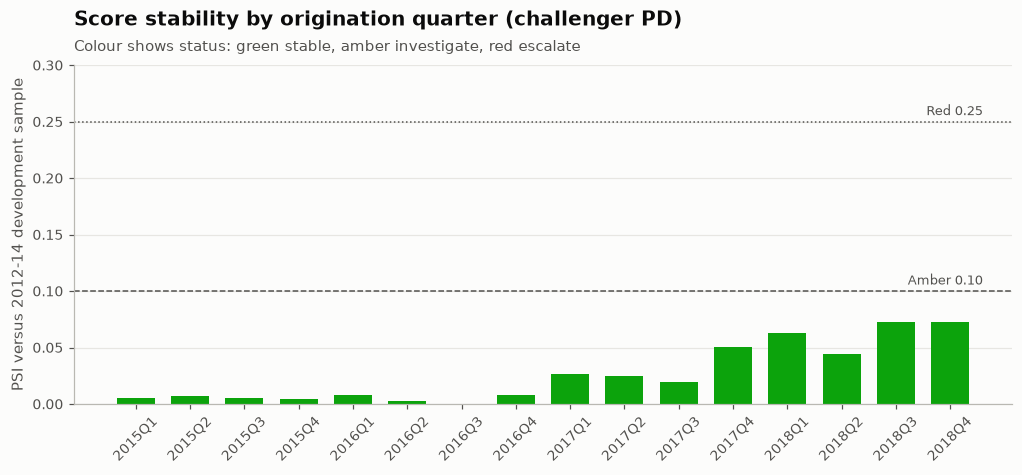

quarter,2015Q1,2015Q2,2015Q3,2015Q4,2016Q1,2016Q2,2016Q3,2016Q4,2017Q1,2017Q2,2017Q3,2017Q4,2018Q1,2018Q2,2018Q3,2018Q4
psi,0.005588,0.006814,0.005237,0.004616,0.008069,0.00254,0.000292,0.008218,0.026702,0.025105,0.019878,0.05011,0.063179,0.043995,0.072729,0.072628
status,Green,Green,Green,Green,Green,Green,Green,Green,Green,Green,Green,Green,Green,Green,Green,Green


In [2]:
dev = pop[pop.dataset_split == "train"]
edges = np.unique(np.quantile(dev.pd_challenger, np.linspace(0, 1, 11)[1:-1]))
def dist(x):
    return np.bincount(np.searchsorted(edges, x), minlength=len(edges) + 1)
expected = dist(dev.pd_challenger)
psi_q = (pop[pop.issue_month >= "2015-01-01"].groupby("quarter").pd_challenger
         .apply(lambda x: psi(expected, dist(x))).rename("psi").reset_index())
psi_q["status"] = pd.cut(psi_q.psi, [-1, 0.10, 0.25, 99], labels=["Green", "Amber", "Red"])

fig, ax = plt.subplots(figsize=(11, 4))
colors = psi_q.status.map({"Green": viz.GOOD, "Amber": viz.WARNING, "Red": viz.CRITICAL})
ax.bar(psi_q.quarter, psi_q.psi, color=colors, width=0.7)
ax.axhline(0.10, color=viz.INK_2, lw=1, ls="--")
ax.axhline(0.25, color=viz.INK_2, lw=1, ls=":")
ax.text(len(psi_q) - 0.4, 0.103, "Amber 0.10", fontsize=8.5, color=viz.INK_2, ha="right", va="bottom")
ax.text(len(psi_q) - 0.4, 0.253, "Red 0.25", fontsize=8.5, color=viz.INK_2, ha="right", va="bottom")
ax.set_ylim(0, max(0.3, psi_q.psi.max() * 1.15))
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("PSI versus 2012-14 development sample")
ax.set_title("Score stability by origination quarter (challenger PD)")
viz.subtitle(ax, "Colour shows status: green stable, amber investigate, red escalate")
plt.show()
psi_q.set_index("quarter").T

## 2. Characteristic stability: which inputs are moving?

When the score drifts, the next question is *why*. The **Characteristic Stability Index** applies the same formula to each input variable. The table shows the most recent quarter against the development sample.

In [3]:
latest_q = pop.quarter.max()
latest = pop[pop.quarter == latest_q]
numeric = [c for c in CHALLENGER_FEATURES if pd.api.types.is_numeric_dtype(pop[c])]
rows = []
for c in numeric:
    x_dev = dev[c].astype(float)
    if x_dev.nunique() < 3:
        continue
    e = np.unique(np.nanquantile(x_dev, np.linspace(0, 1, 11)[1:-1]))
    def d_(x):
        x = x.astype(float).to_numpy()
        idx = np.where(np.isnan(x), len(e) + 1, np.searchsorted(e, x))
        return np.bincount(idx, minlength=len(e) + 2)
    rows.append({"variable": c, "csi": psi(d_(x_dev), d_(latest[c])),
                 "dev_median": x_dev.median(), "latest_median": latest[c].astype(float).median()})
csi = pd.DataFrame(rows).sort_values("csi", ascending=False)
csi["status"] = pd.cut(csi.csi, [-1, 0.10, 0.25, 99], labels=["Green", "Amber", "Red"])
print(f"Latest quarter: {latest_q}")
liens = pop[pop.issue_month >= "2016-01-01"].groupby("quarter").tax_liens.apply(lambda x: (x > 0).mean())
print("Share of applicants with a tax lien on file:", " | ".join(f"{q} {v:.1%}" for q, v in liens.items()))
csi.head(12).style.format({"csi": "{:.3f}", "dev_median": "{:,.3f}", "latest_median": "{:,.3f}"}).hide(axis="index")

Latest quarter: 2018Q4
Share of applicants with a tax lien on file: 2016Q1 4.3% | 2016Q2 4.3% | 2016Q3 4.6% | 2016Q4 4.7% | 2017Q1 4.8% | 2017Q2 4.6% | 2017Q3 2.6% | 2017Q4 2.4% | 2018Q1 2.4% | 2018Q2 0.6% | 2018Q3 0.0% | 2018Q4 0.0%


variable,csi,dev_median,latest_median,status
tax_liens,0.505,0.000,0.000,Red
pct_bankcards_over_75_util,0.339,0.500,0.250,Red
bankcard_utilization,0.309,0.704,0.495,Red
revolving_utilization,0.287,0.581,0.424,Red
bankcard_open_to_buy,0.285,"3,581.000","8,417.000",Red
total_revolving_limit,0.160,"22,800.000","29,700.000",Amber
inquiries_6m,0.136,0.000,0.000,Amber
months_since_oldest_revolving,0.136,165.000,155.000,Amber
fico_score,0.126,692.000,702.000,Amber
annual_income,0.113,"63,500.000","75,000.000",Amber


## 3. Performance over time: does the model still rank risk?

Discrimination can only be measured once outcomes are known: every quarter from 2015 to Q1 2017 has a mature 24-month outcome. Lending Club's own grade is shown on the same loans as a benchmark.

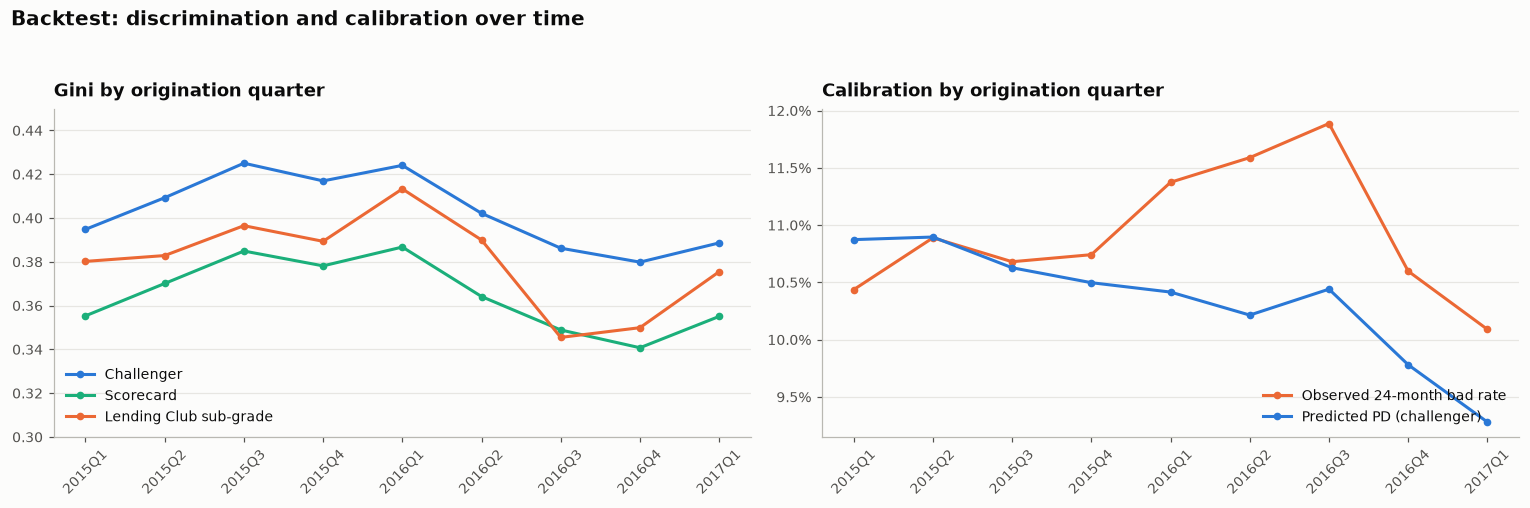

quarter,loans,observed_bad_rate,predicted_pd,gini_challenger,gini_scorecard,gini_lending_club,calibration_gap
2015Q1,"84,277",10.44%,10.87%,0.395,0.355,0.380,-0.44%
2015Q2,"95,825",10.89%,10.90%,0.409,0.370,0.383,-0.01%
2015Q3,"110,489",10.68%,10.63%,0.425,0.385,0.397,+0.05%
2015Q4,"130,504",10.74%,10.50%,0.417,0.378,0.389,+0.24%
2016Q1,"133,887",11.37%,10.42%,0.424,0.387,0.413,+0.96%
2016Q2,"97,854",11.59%,10.21%,0.402,0.364,0.390,+1.37%
2016Q3,"99,120",11.89%,10.44%,0.386,0.349,0.345,+1.45%
2016Q4,"103,546",10.60%,9.78%,0.380,0.341,0.350,+0.82%
2017Q1,"96,779",10.09%,9.28%,0.389,0.355,0.375,+0.81%


In [4]:
grades = [f"{g}{i}" for g in "ABCDEFG" for i in range(1, 6)]
rank = {g: i for i, g in enumerate(grades)}
lab = pop[pop[TARGET].notna() & (pop.issue_month >= "2015-01-01")]
perf = lab.groupby("quarter").apply(lambda g: pd.Series({
    "loans": len(g),
    "observed_bad_rate": g[TARGET].mean(),
    "predicted_pd": g.pd_challenger.mean(),
    "gini_challenger": 2 * roc_auc_score(g[TARGET], g.pd_challenger) - 1,
    "gini_scorecard": 2 * roc_auc_score(g[TARGET], g.pd_scorecard) - 1,
    "gini_lending_club": 2 * roc_auc_score(g[TARGET], g.benchmark_sub_grade.astype(str).map(rank)) - 1,
}), include_groups=False).reset_index()
perf["calibration_gap"] = perf.observed_bad_rate - perf.predicted_pd

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
for col, color, name in [("gini_challenger", viz.BLUE, "Challenger"), ("gini_scorecard", viz.AQUA, "Scorecard"),
                         ("gini_lending_club", viz.ORANGE, "Lending Club sub-grade")]:
    ax.plot(perf.quarter, perf[col], color=color, marker="o", ms=4, label=name)
ax.set_ylim(0.3, 0.45)
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower left")
ax.set_title("Gini by origination quarter", fontsize=11.5, pad=8)
ax = axes[1]
ax.plot(perf.quarter, perf.observed_bad_rate, color=viz.ORANGE, marker="o", ms=4, label="Observed 24-month bad rate")
ax.plot(perf.quarter, perf.predicted_pd, color=viz.BLUE, marker="o", ms=4, label="Predicted PD (challenger)")
viz.pct(ax, decimals=1)
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower right")
ax.set_title("Calibration by origination quarter", fontsize=11.5, pad=8)
fig.suptitle("Backtest: discrimination and calibration over time", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
plt.show()
perf.style.format({"loans": "{:,.0f}", "observed_bad_rate": "{:.2%}", "predicted_pd": "{:.2%}", "gini_challenger": "{:.3f}",
                   "gini_scorecard": "{:.3f}", "gini_lending_club": "{:.3f}", "calibration_gap": "{:+.2%}"}).hide(axis="index")

## 4. Segment check

A model can be accurate overall and still be wrong for one group. Without protected attributes in the data, the check uses the segments available: census region, home ownership and loan term. For each, the model should rank risk similarly well and its calibration gap should be similar. Large differences would call for a fairness review.

In [5]:
geo = connect().execute("select state_code, census_region from gold.dim_geography").df()
seg_pop = pop[pop.dataset_split == "test_oot"].merge(geo, on="state_code", how="left")
seg_pop["home_ownership"] = seg_pop.home_ownership.astype(str)
seg_rows = []
for col in ["census_region", "home_ownership", "term_months"]:
    for level, g in seg_pop.groupby(col):
        if len(g) < 5000:
            continue
        seg_rows.append({"segment": col, "level": str(level), "loans": len(g),
                         "observed_bad_rate": g[TARGET].mean(), "predicted_pd": g.pd_challenger.mean(),
                         "gini": 2 * roc_auc_score(g[TARGET], g.pd_challenger) - 1})
seg = pd.DataFrame(seg_rows)
seg["calibration_gap"] = seg.observed_bad_rate - seg.predicted_pd
seg.style.format({"loans": "{:,.0f}", "observed_bad_rate": "{:.2%}", "predicted_pd": "{:.2%}", "gini": "{:.3f}",
                  "calibration_gap": "{:+.2%}"}).hide(axis="index")

segment,level,loans,observed_bad_rate,predicted_pd,gini,calibration_gap
census_region,Midwest,"75,984",10.80%,9.98%,0.408,+0.82%
census_region,Northeast,"82,522",11.38%,10.31%,0.388,+1.07%
census_region,South,"152,728",11.64%,10.39%,0.397,+1.24%
census_region,West,"103,383",11.58%,10.31%,0.407,+1.26%
home_ownership,MORTGAGE,"211,516",9.52%,8.85%,0.410,+0.68%
home_ownership,OWN,"53,037",11.42%,10.09%,0.365,+1.33%
home_ownership,RENT,"169,744",13.62%,11.99%,0.375,+1.63%
term_months,36,"323,495",10.39%,9.36%,0.389,+1.03%
term_months,60,"110,912",14.17%,12.74%,0.401,+1.43%


## 5. Monitoring framework

The checks above become a monthly report with fixed thresholds. Each metric has an owner and a predefined action, so a breach leads to a decision rather than a discussion.

In [6]:
latest_perf = perf.iloc[-1]
latest_psi = psi_q.iloc[-1]
framework = pd.DataFrame([
    ("Score PSI vs development", f"{latest_psi.psi:.3f} ({latest_psi.quarter})", "below 0.10", "0.10 to 0.25", "above 0.25",
     "Model owner: investigate drivers via CSI"),
    ("Worst input CSI", f"{csi.csi.max():.3f} ({csi.iloc[0].variable})", "below 0.10", "0.10 to 0.25", "above 0.25",
     "Data owner: confirm source change or genuine shift"),
    ("Gini, latest mature quarter", f"{latest_perf.gini_challenger:.3f} ({latest_perf.quarter})", "above 0.36", "0.32 to 0.36", "below 0.32",
     "Model owner: challenger refresh; validation review if red"),
    ("Calibration gap (observed - predicted)", f"{latest_perf.calibration_gap:+.2%}", "within 1 pt", "1 to 2 pts", "above 2 pts",
     "Recalibrate intercept on latest mature year"),
    ("Expected vs realised loss by vintage", "Notebook 08 backtest", "within 10%", "10% to 25%", "above 25%",
     "Finance: provision overlay; risk: lifetime-ratio update"),
], columns=["metric", "latest_value", "green", "amber", "red", "action_owner"])
framework.style.hide(axis="index")

metric,latest_value,green,amber,red,action_owner
Score PSI vs development,0.073 (2018Q4),below 0.10,0.10 to 0.25,above 0.25,Model owner: investigate drivers via CSI
Worst input CSI,0.505 (tax_liens),below 0.10,0.10 to 0.25,above 0.25,Data owner: confirm source change or genuine shift
"Gini, latest mature quarter",0.389 (2017Q1),above 0.36,0.32 to 0.36,below 0.32,Model owner: challenger refresh; validation review if red
Calibration gap (observed - predicted),+0.81%,within 1 pt,1 to 2 pts,above 2 pts,Recalibrate intercept on latest mature year
Expected vs realised loss by vintage,Notebook 08 backtest,within 10%,10% to 25%,above 25%,Finance: provision overlay; risk: lifetime-ratio update


## 6. Findings

**1. The score is stable even though its inputs moved.** Score PSI stays green in every quarter from 2015 to 2018 (highest 0.07 in late 2018). Shifts in individual inputs partly offset each other, so the overall risk distribution the model sees has barely changed.

**2. Input drift is real and has two very different causes.** The CSI table shows several red inputs in Q4 2018:

- **A data-source change: tax liens (CSI 0.51).** The share of applicants with a tax lien on file fell from about 4.8% in early 2017 to 2.6% in Q3 2017 and to zero from Q3 2018. This is not a change in borrowers. Under the National Consumer Assistance Plan, the US credit bureaus removed about half of tax liens from credit reports in July 2017 and all of them by April 2018 ([CFPB, 2019](https://files.consumerfinance.gov/f/documents/cfpb_quarterly-consumer-credit-trends_public-records-credit-scores-performance_2019-12.pdf)). Monitoring caught a regulatory change in the data supply chain, which is exactly what CSI is for. The variable has almost no weight in the model (IV below 0.001), so the impact is nil, but a model that relied on it would need redevelopment.
- **A borrower change: utilisation and FICO.** Median bankcard utilisation fell from 70% to 50% and median FICO rose from 692 to 702. Lending Club tightened its credit policy in 2017 and 2018, and more borrowers used the loan to pay down cards before applying. These are genuine population shifts that the model's inputs reflect correctly.

**3. Ranking power is stable.** The challenger's Gini stays between 0.38 and 0.43 in every mature quarter and is above both the scorecard and Lending Club's own grade in each of them.

**4. Calibration drifts with the cycle, as expected.** The model was calibrated on 2015. The calibration gap reached +1.5 points (amber) in Q3 2016, when the market was at its riskiest, then fell back to +0.8 points (green) in Q1 2017 as Lending Club tightened. This is the check that triggers the intercept recalibration from notebooks 06 and 07.

**5. Segments.** Gini ranges from 0.37 to 0.41 across regions, home ownership and term, so the model ranks risk comparably in every segment. The model under-predicts slightly more for renters (+1.6 points) and 60-month loans (+1.4 points), the groups that deteriorated most in 2016. That is a calibration item for the quarterly review, not a ranking failure.

## 7. Model card and monitoring exports

In [7]:
cmp_ = pd.read_csv(REPORTS / "pd_model_comparison.csv").set_index("dataset")
card = f"""# Model card: Meridian PD challenger (LightGBM)

| Field | Value |
|---|---|
| Purpose | Probability that a consumer loan defaults within 24 months of issue; input to funding decisions, pricing and Expected Loss |
| Owner | Credit Risk Analytics (Meridian Capital, fictional) |
| Status | Champion for funding decisions; 16-variable WoE scorecard kept as benchmark and fallback |
| Training data | Lending Club loans issued 2012-01 to 2014-12 (423,810 loans), application-time information only |
| Target | Charge-off within 24 months of issue (estimated charge-off date = last payment + 5 months) |
| Validation | Early stopping and Platt calibration on 2015 loans; one-time out-of-time test on 2016 loans |
| Algorithm | LightGBM gradient boosting, {len(CHALLENGER_FEATURES)} inputs, monotonic constraints on numeric inputs with IV >= 0.02 |
| Out-of-time Gini (2016) | {cmp_.loc['Meridian challenger (LightGBM, 47 variables)', 'gini']:.3f} (scorecard {cmp_.loc['Meridian scorecard (16 variables)', 'gini']:.3f}, Lending Club grade {cmp_.loc['Lending Club sub-grade (benchmark)', 'gini']:.3f}) |
| Out-of-time KS (2016) | {cmp_.loc['Meridian challenger (LightGBM, 47 variables)', 'ks']:.3f} |
| Explainability | Exact TreeSHAP per decision; top 3 positive contributions are the adverse-action reasons |
| Known limitations | Accepted loans only (no reject inference); calibration drifts with the credit cycle; state of residence carries weight and requires fair-lending review |
| Monitoring | Monthly: score PSI, input CSI. Quarterly: Gini and calibration on newly matured quarter, EL versus realised loss by vintage |
| Retraining triggers | PSI > 0.25, Gini < 0.32, or calibration gap > 2 points for two consecutive quarters |
"""
(config.PROJECT_ROOT / "docs").mkdir(exist_ok=True)
(config.PROJECT_ROOT / "docs" / "model_card_pd.md").write_text(card)
APP.mkdir(exist_ok=True)
psi_q.assign(status=psi_q.status.astype(str)).to_parquet(APP / "monitoring_psi.parquet", index=False)
csi.assign(status=csi.status.astype(str)).to_parquet(APP / "monitoring_csi.parquet", index=False)
perf.to_parquet(APP / "monitoring_performance.parquet", index=False)
print(card)

# Model card: Meridian PD challenger (LightGBM)

| Field | Value |
|---|---|
| Purpose | Probability that a consumer loan defaults within 24 months of issue; input to funding decisions, pricing and Expected Loss |
| Owner | Credit Risk Analytics (Meridian Capital, fictional) |
| Status | Champion for funding decisions; 16-variable WoE scorecard kept as benchmark and fallback |
| Training data | Lending Club loans issued 2012-01 to 2014-12 (423,810 loans), application-time information only |
| Target | Charge-off within 24 months of issue (estimated charge-off date = last payment + 5 months) |
| Validation | Early stopping and Platt calibration on 2015 loans; one-time out-of-time test on 2016 loans |
| Algorithm | LightGBM gradient boosting, 47 inputs, monotonic constraints on numeric inputs with IV >= 0.02 |
| Out-of-time Gini (2016) | 0.401 (scorecard 0.363, Lending Club grade 0.378) |
| Out-of-time KS (2016) | 0.293 |
| Explainability | Exact TreeSHAP per decision; top 3 positive con

## 8. Conclusions

1. The challenger is **fit for use**: it ranks risk consistently better than the scorecard in every mature quarter and holds its own against Lending Club's grade.
2. The main production risk is **calibration drift** as the credit cycle turns, not a loss of ranking power. The monitoring framework catches it quarterly and the response is a cheap recalibration, not a rebuild.
3. **Population drift** is real and explainable. It is tracked monthly with PSI and traced to specific inputs with CSI.
4. The model card documents purpose, data, performance, limitations and triggers in one page, ready for a model risk committee.

**Next:** notebook 13 puts an AI analyst on top of the governed warehouse, so stakeholders can ask these questions in plain English.